# Heart Disease Prediction — Improved Machine Learning Project

A revised version of a 2022 college project. This notebook compares classification models using a deduplicated public dataset and leakage-safe preprocessing. **Educational demonstration only; not a clinical diagnostic tool.**

**Dataset:** Kaggle *Heart Disease Dataset* (`johnsmith88/heart-disease-dataset`). Download `heart.csv` and upload it to Colab before running. The source dataset contains 1,025 rows, including 723 duplicate rows.

## 1. Load and inspect the data

In [3]:
from google.colab import files
uploaded = files.upload()

Saving archive.zip to archive (1).zip


In [4]:
import os
print(os.listdir('/content'))

['.config', 'archive.zip', 'archive (1).zip', 'sample_data']


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Upload heart.csv to the Colab session, or place it alongside this notebook.
heart_data = pd.read_csv('/content/archive.zip', compression='zip')
print(heart_data.shape)
print('Original shape:', heart_data.shape)
print('Missing values:', heart_data.isna().sum().sum())
print('Duplicate rows:', heart_data.duplicated().sum())
display(heart_data.head())

(1025, 14)
Original shape: (1025, 14)
Missing values: 0
Duplicate rows: 723


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## 2. Remove duplicates and explore the target

Duplicate removal is performed **before** splitting to avoid identical records appearing in training and testing.

Unique records: 302
Target distribution:
target
0    138
1    164
Name: count, dtype: int64


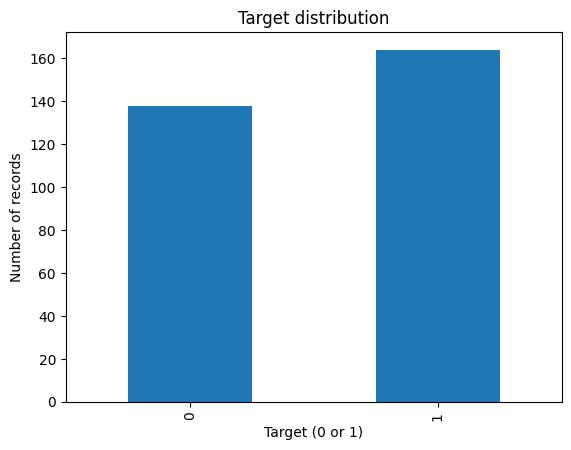

In [6]:
heart_clean = heart_data.drop_duplicates().copy()
X = heart_clean.drop(columns='target')
y = heart_clean['target']
print('Unique records:', len(heart_clean))
print('Target distribution:')
print(y.value_counts().sort_index())
y.value_counts().sort_index().plot(kind='bar', title='Target distribution')
plt.xlabel('Target (0 or 1)')
plt.ylabel('Number of records')
plt.show()

## 3. Train/test split

Use the same stratified 80/20 split for all baseline models. Preprocessing is fitted on training data only.

In [7]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print('Train:', len(X_train), '| Test:', len(X_test))

Train: 241 | Test: 61


## 4. Baseline models

Compare Logistic Regression, Naive Bayes, KNN (K=12), and Random Forest on the same test set.

In [8]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Naive Bayes': Pipeline([
        ('scaler', StandardScaler()), ('model', GaussianNB())
    ]),
    'KNN (K=12)': Pipeline([
        ('scaler', StandardScaler()), ('model', KNeighborsClassifier(n_neighbors=12))
    ]),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=5, random_state=42
    )
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

## 5. Improved KNN

Scale continuous variables, one-hot encode categorical variables, and tune the number of neighbors **using training data only**.

In [9]:
numeric_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_features),
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

knn_grid = {'classifier__n_neighbors': [3, 5, 7, 9, 11, 12, 15, 17, 19, 21]}
knn_search = GridSearchCV(knn_pipeline, knn_grid, cv=5, scoring='accuracy', n_jobs=-1)
knn_search.fit(X_train, y_train)
predictions['Improved KNN'] = knn_search.predict(X_test)
print('Best K:', knn_search.best_params_['classifier__n_neighbors'])
print('Training CV accuracy:', round(knn_search.best_score_ * 100, 2), '%')

Best K: 5
Training CV accuracy: 83.82 %


## 5.1. Improved KNN – Classification Report and Confusion Matrix

This section evaluates the improved K-Nearest Neighbors (KNN) model using precision, recall, F1-score, and a confusion matrix.

The model achieved **83.61% test accuracy**. For patients labeled with heart disease (Class 1), it achieved:

- **Precision:** 87.10%
- **Recall:** 81.82%
- **F1-score:** 84.40%

The confusion matrix shows that the model correctly identified 27 of 33 positive cases, while missing 6.

Recall is particularly important in this classification task because false negatives represent heart disease cases incorrectly classified as negative. These results are based on a small test dataset and do not establish clinical reliability.


Improved KNN - Classification Report
              precision    recall  f1-score   support

           0      0.800     0.857     0.828        28
           1      0.871     0.818     0.844        33

    accuracy                          0.836        61
   macro avg      0.835     0.838     0.836        61
weighted avg      0.838     0.836     0.836        61



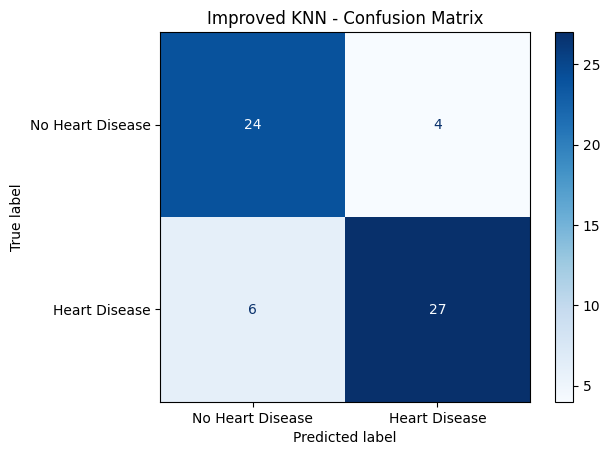

In [12]:

from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predictions from the improved KNN model
predictions = knn_search.predict(X_test)

print("Improved KNN - Classification Report")
print(classification_report(y_test, predictions, digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["No Heart Disease", "Heart Disease"],
    cmap="Blues"
)

plt.title("Improved KNN - Confusion Matrix")
plt.show()


In [17]:
print("Models:", list(models.keys()))
print("Predictions type:", type(predictions))
print("Test records:", len(y_test))


Models: ['Logistic Regression', 'Naive Bayes', 'KNN (K=12)', 'Random Forest']
Predictions type: <class 'numpy.ndarray'>
Test records: 61



### 5.2 Five-Model Classification Metrics Comparison

This section compares all five machine learning models using the same held-out test set of 61 records.

In addition to accuracy, precision, recall, and F1-score are calculated for the positive class (target = 1), representing heart disease.

These metrics help assess how effectively each model identifies positive cases and highlight differences that accuracy alone may not reveal.


In [18]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

all_models = {**models, "Improved KNN (Tuned)": knn_search}

metrics_results = []

for name, model in all_models.items():
    y_pred = model.predict(X_test)

    metrics_results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_test, y_pred, pos_label=1, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_test, y_pred, pos_label=1, zero_division=0) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, y_pred, pos_label=1, zero_division=0) * 100, 2)
    })

metrics_df = pd.DataFrame(metrics_results)
display(metrics_df)


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Logistic Regression,80.33,80.00,84.85,82.35
1,Naive Bayes,78.69,83.33,75.76,79.37
2,KNN (K=12),80.33,80.00,84.85,82.35
3,Random Forest,77.05,78.79,78.79,78.79
4,Improved KNN (Tuned),83.61,87.10,81.82,84.38



**Interpretation:**

Improved KNN achieved the highest accuracy (83.61%), precision (87.10%), and F1-score (84.38%) on the held-out test set.

Logistic Regression and baseline KNN achieved the highest recall (84.85%), identifying a larger proportion of positive heart disease cases.

These results demonstrate the trade-off between precision and recall. Since the test set contains only 61 records, the observed differences should be interpreted cautiously.


## 6. Compare test-set results

Precision, recall, and F1 below use target class `1` as the positive class.

In [10]:
results = []
for name, pred in predictions.items():
    results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test, pred) * 100, 2),
        'Precision (%)': round(precision_score(y_test, pred) * 100, 2),
        'Recall (%)': round(recall_score(y_test, pred) * 100, 2),
        'F1 (%)': round(f1_score(y_test, pred) * 100, 2)
    })
results_df = pd.DataFrame(results).sort_values('Accuracy (%)', ascending=False)
display(results_df)
print('Improved KNN classification report:')
print(classification_report(y_test, predictions['Improved KNN']))

,Model,Accuracy (%),Precision (%),Recall (%),F1 (%)
4,Improved KNN,83.61,87.10,81.82,84.38
0,Logistic Regression,80.33,80.00,84.85,82.35
2,KNN (K=12),80.33,80.00,84.85,82.35
1,Naive Bayes,78.69,83.33,75.76,79.37
3,Random Forest,77.05,78.79,78.79,78.79


Improved KNN classification report:
              precision    recall  f1-score   support

           0       0.80      0.86      0.83        28
           1       0.87      0.82      0.84        33

    accuracy                           0.84        61
   macro avg       0.84      0.84      0.84        61
weighted avg       0.84      0.84      0.84        61



## 7. Nested cross-validation for improved KNN

Each outer fold is evaluated on data excluded from its inner tuning process. This provides a more defensible performance estimate than choosing a model based only on repeated checks of one test split. **This nested-CV result evaluates KNN, not every model in the table above.**

In [11]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=21)

nested_search = GridSearchCV(
    knn_pipeline,
    {'classifier__n_neighbors': [3, 5, 7, 9, 11, 15, 19]},
    cv=inner_cv,
    scoring='accuracy'
)
nested_scores = cross_val_score(nested_search, X, y, cv=outer_cv, scoring='accuracy')
print('Fold accuracies (%):', np.round(nested_scores * 100, 2))
print('Mean accuracy (%):', round(nested_scores.mean() * 100, 2))
print('Standard deviation (%):', round(nested_scores.std() * 100, 2))

Fold accuracies (%): [80.33 85.25 75.   88.33 75.  ]
Mean accuracy (%): 80.78
Standard deviation (%): 5.37


## 8. Cross-Validation Comparison of All Five Models

This section compares the performance of five machine learning model configurations: Logistic Regression, Gaussian Naive Bayes, baseline KNN, Random Forest, and improved KNN.

All models will be evaluated using the same five-fold cross-validation splits to ensure a consistent comparison. Preprocessing will be performed within each training fold to prevent data leakage.

The results will be summarized using **mean accuracy ± standard deviation**, allowing us to compare average performance and variability across folds.

This comparison provides a more reliable assessment than relying solely on accuracy from a single train-test split.

In [13]:

from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.base import clone
import pandas as pd

# Use identical folds for all models
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

# Four baseline models
for name, model in models.items():
    scores = cross_val_score(
        clone(model), X_train, y_train,
        cv=cv, scoring="accuracy"
    )
    results.append({
        "Model": name,
        "Mean Accuracy (%)": round(scores.mean() * 100, 2),
        "Std Dev (pp)": round(scores.std() * 100, 2)
    })

# Improved KNN: tune only within each training fold
tuned_knn = GridSearchCV(
    knn_pipeline,
    knn_grid,
    cv=3,
    scoring="accuracy"
)

scores = cross_val_score(
    tuned_knn, X_train, y_train,
    cv=cv, scoring="accuracy"
)

results.append({
    "Model": "Improved KNN (Tuned)",
    "Mean Accuracy (%)": round(scores.mean() * 100, 2),
    "Std Dev (pp)": round(scores.std() * 100, 2)
})

comparison_df = pd.DataFrame(results)
comparison_df["Mean ± Std Dev (%)"] = comparison_df.apply(
    lambda row: f"{row['Mean Accuracy (%)']:.2f} ± {row['Std Dev (pp)']:.2f}",
    axis=1
)

display(comparison_df[["Model", "Mean ± Std Dev (%)"]])


,Model,Mean ± Std Dev (%)
0,Logistic Regression,83.79 ± 8.61
1,Naive Bayes,81.72 ± 4.89
2,KNN (K=12),80.88 ± 4.90
3,Random Forest,85.88 ± 6.12
4,Improved KNN (Tuned),83.79 ± 4.88


In [14]:
import importlib.metadata as metadata

for package in ["numpy", "pandas", "scikit-learn", "matplotlib"]:
    print(f"{package}=={metadata.version(package)}")

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0


## 9. Findings and Limitations

**Key Findings:** Improved KNN achieved **83.61% accuracy** on the held-out test set of 61 records, with **81.82% recall** and **84.40% F1-score** for heart disease cases.

In the five-model cross-validation comparison, Random Forest achieved the highest mean accuracy (**85.88% ± 6.12 percentage points**), followed by Logistic Regression and tuned KNN (**83.79%** each).

The earlier nested five-fold cross-validation experiment for tuned KNN achieved **80.78% mean accuracy**, with a standard deviation of **5.37 percentage points**. This used a different evaluation setup from the new comparison.

**Limitations:** After removing duplicates, only 302 unique records remained. The held-out test set contained just 61 records, making performance estimates sensitive to individual predictions. The differences between cross-validation scores do not establish that one model is definitively better.

Multiple model configurations were explored using the same held-out test set, so the highest observed test accuracy should be considered exploratory rather than an unbiased estimate of future performance.

This project is intended for educational purposes and should not be used for clinical decision-making.

**Comparison with the Original 2022 Project:** The original notebook used all 1,025 records and different preprocessing and evaluation methods. Therefore, its reported accuracy is not directly comparable with the updated version.